# Feed Amount Analysis - Log-Normal Kalman Filter

This notebook estimates feed consumption rate from per-frame YOLO bounding box areas.

**Theory:** YOLO detection noise is multiplicative (proportional to box size), not additive.
Taking `log(area)` converts it to additive Gaussian noise, enabling optimal Kalman filtering.

Key features:
- 2D state vector: `[log_area, consumption_rate]` — rate estimated jointly, not by finite difference
- Unbiased area recovery: `exp(μ + P₁₁/2)` corrects Log-Normal bias
- 1-sigma confidence interval from filter covariance
- True one-step-ahead prediction via constant-velocity model

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
from scipy.ndimage import uniform_filter1d
import warnings
warnings.filterwarnings('ignore')

# Set default font
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

## 1. Kalman Filter Implementation

In [2]:
class LogNormalKalmanFilter:
    """
    2D Log-Normal Kalman Filter for feed area estimation.
    **IMPROVED VERSION** with zero-value handling and outlier robustness.

    State vector: x = [mu, mu_dot]
      mu      = log(true feed area)          — position in log space
      mu_dot  = d(log A)/dt                  — relative consumption rate [1/frame]

    Observation: y_t = log(z_t) = mu_t + v_t,  v_t ~ N(0, sigma_R^2)

    Key improvements:
      - Skip zero measurements (detection failures) without corrupting state
      - Reject outliers by inflating measurement noise for extreme deviations
      - Optional backward smoothing (RTS) to remove amplitude-amplifying artifacts
    """

    def __init__(self, sigma_R: float = 0.15, sigma_Q: float = 1e-3, dt: float = 1.0,
                 reject_outliers: bool = True, outlier_threshold: float = 3.0):
        """
        Args:
            sigma_R: Measurement noise std in log space (±15% ≈ 0.15).
            sigma_Q: Process noise intensity (larger = faster rate tracking).
                     **Recommended: increase to 5e-3 or 1e-2 to reduce spike artifacts**
            dt:      Time step in frames (default 1).
            reject_outliers: Skip measurements > 3σ deviation from prediction.
            outlier_threshold: Detection threshold in std units (default 3.0).
        """
        self.dt = dt
        self.sigma_R = sigma_R
        self.reject_outliers = reject_outliers
        self.outlier_threshold = outlier_threshold

        self.x = np.zeros(2)
        self.P = np.eye(2)

        self.F = np.array([[1.0, dt],
                           [0.0, 1.0]])
        self.h = np.array([1.0, 0.0])

        self.Q = sigma_Q * np.array([
            [dt ** 4 / 4, dt ** 3 / 2],
            [dt ** 3 / 2, dt ** 2    ]
        ])

        self.R_scalar = sigma_R ** 2
        self.initialized = False

        # Storage for RTS smoothing
        self.history_x = []
        self.history_P = []

    def update(self, area_measurement: float) -> float:
        """
        **Improved:** Skip zero measurements, optionally reject outliers.
        """
        # Skip detection failures (zero area)
        if area_measurement <= 0:
            return self.area_estimate if self.initialized else 0.0

        y = np.log(max(area_measurement, 1e-9))

        if not self.initialized:
            self.x = np.array([y, 0.0])
            self.P = np.diag([self.sigma_R ** 2, 1.0])
            self.initialized = True
            return self.area_estimate

        # ── Predict ──────────────────────────────────────────────
        x_pred = self.F @ self.x
        P_pred = self.F @ self.P @ self.F.T + self.Q

        # ── Outlier rejection (optional) ──────────────────────────
        innovation = y - self.h @ x_pred
        S = self.h @ P_pred @ self.h + self.R_scalar

        if self.reject_outliers and abs(innovation) > self.outlier_threshold * np.sqrt(S):
            # Reject outlier: skip update, just predict
            self.x = x_pred
            self.P = P_pred
            return self.area_estimate

        # ── Standard KF update ───────────────────────────────────
        K = (P_pred @ self.h) / S
        self.x = x_pred + K * innovation
        self.P = (np.eye(2) - np.outer(K, self.h)) @ P_pred

        # Store for RTS smoothing
        self.history_x.append(self.x.copy())
        self.history_P.append(self.P.copy())

        return self.area_estimate

    def rts_smooth(self):
        """
        Rauch-Tung-Striebel smoother: backward pass to reduce spike artifacts.
        Call after forward filtering completes.
        """
        if len(self.history_x) < 2:
            return

        n = len(self.history_x)
        x_smooth = [self.history_x[-1]]

        for k in range(n - 2, -1, -1):
            x_pred_next = self.F @ self.history_x[k]
            P_pred_next = self.F @ self.history_P[k] @ self.F.T + self.Q

            C = self.history_P[k] @ self.F.T @ np.linalg.inv(P_pred_next)
            x_smooth.insert(0, self.history_x[k] + C @ (x_smooth[0] - x_pred_next))

        self.history_x = x_smooth
        self.x = x_smooth[-1]

    def predict_next(self) -> float:
        """True one-step-ahead prediction using the velocity state."""
        x_next = self.F @ self.x
        P_next = self.F @ self.P @ self.F.T + self.Q
        return np.exp(x_next[0] + P_next[0, 0] / 2)

    @property
    def area_estimate(self) -> float:
        """Unbiased area estimate: E[A] = exp(mu + P₁₁/2)."""
        return np.exp(self.x[0] + self.P[0, 0] / 2)

    @property
    def consumption_rate(self) -> float:
        """Relative consumption rate d(log A)/dt  [1/frame]."""
        return self.x[1]

    @property
    def area_confidence_interval(self):
        """1-sigma confidence interval in area space: (lower, upper)."""
        log_std = np.sqrt(self.P[0, 0])
        return np.exp(self.x[0] - log_std), np.exp(self.x[0] + log_std)

## 2. Configuration Parameters

In [3]:
CONFIG = {
    'video_path': 'data/fish_feeding.mp4',
    'model_path': 'models/yoloFish.pt',
    'confidence_threshold': 0.35,
    'device': 'cuda',

    # Log-Normal Kalman Filter parameters
    'sigma_R': 0.15,

    # sigma_Q: CRITICAL — increase from 1e-3 to 1e-2 for better handling of spikes
    # From sweep: sigma_Q=1e-2 (reject_outliers=False) gives best log-MAE (0.527)
    'sigma_Q': 1e-2,  # ← CHANGED: 1e-3 → 1e-2 (10x increase)

    # Disable outlier rejection — causes more harm than good with spotty detections
    'reject_outliers': False,
    'outlier_threshold': 3.0,

    'max_frames': None,
}

print("Configuration parameters:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Configuration parameters:
  video_path: data/fish_feeding.mp4
  model_path: models/yoloFish.pt
  confidence_threshold: 0.35
  device: cuda
  sigma_R: 0.15
  sigma_Q: 0.01
  reject_outliers: False
  outlier_threshold: 3.0
  max_frames: None


## 3. Load Model and Video

In [4]:
# 加載 YOLO 模型
print(f"加載模型: {CONFIG['model_path']}")
model = YOLO(CONFIG['model_path'])
model.to(CONFIG['device'])

# 打開視頻
video_path = CONFIG['video_path']
print(f"\n加載視頻: {video_path}")
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError(f"無法打開視頻: {video_path}")

# 取得視頻信息
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"視頻信息:")
print(f"  總幀數: {total_frames}")
print(f"  FPS: {fps}")
print(f"  解像度: {width}x{height}")
print(f"  總時長: {total_frames/fps:.2f}秒")

加載模型: models/yoloFish.pt

加載視頻: data/fish_feeding.mp4
視頻信息:
  總幀數: 563
  FPS: 30.0
  解像度: 1920x1080
  總時長: 18.77秒


## 4. Run Inference and Calculate Feed Area

In [5]:
# Data storage
frame_numbers    = []
feed_areas_raw   = []   # raw YOLO measurement
feed_areas_filtered = []  # Log-Normal KF estimate (unbiased)
consumption_rates   = []  # relative rate d(log A)/dt  [1/frame]
predictions      = []   # true 1-step-ahead area prediction
conf_upper       = []   # 1-sigma upper bound
conf_lower       = []   # 1-sigma lower bound

# Initialise Log-Normal Kalman Filter with improved parameters
kf = LogNormalKalmanFilter(
    sigma_R=CONFIG['sigma_R'],
    sigma_Q=CONFIG['sigma_Q'],  # Increased to 1e-2
    dt=1.0,
    reject_outliers=CONFIG['reject_outliers'],  # False
    outlier_threshold=CONFIG['outlier_threshold'],
)

frame_idx  = 0
max_frames = CONFIG['max_frames'] or total_frames

print(f"開始推論，共 {min(max_frames, total_frames)} 幀...")
print(f"信心度閾值: {CONFIG['confidence_threshold']}")
print(f"sigma_R={CONFIG['sigma_R']},  sigma_Q={CONFIG['sigma_Q']}")
print(f"異常值拒絕: {CONFIG['reject_outliers']}")
print()

開始推論，共 563 幀...
信心度閾值: 0.35
sigma_R=0.15,  sigma_Q=0.01
異常值拒絕: False



In [6]:
import sys

while frame_idx < max_frames:
    ret, frame = cap.read()
    if not ret:
        print(f"\n到達視頻末尾在 Frame {frame_idx}")
        break

    results = model(frame, conf=CONFIG['confidence_threshold'], verbose=False)

    frame_feed_area = 0.0
    if len(results) > 0:
        result = results[0]
        if result.boxes is not None and len(result.boxes) > 0:
            for box in result.boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                frame_feed_area += (x2 - x1) * (y2 - y1)

    frame_numbers.append(frame_idx)
    feed_areas_raw.append(frame_feed_area)

    # Log-Normal KF: input raw area, get unbiased filtered area
    filtered = kf.update(frame_feed_area)
    feed_areas_filtered.append(filtered)
    consumption_rates.append(kf.consumption_rate)

    # True 1-step-ahead prediction (uses velocity state)
    predictions.append(kf.predict_next())

    lo, hi = kf.area_confidence_interval
    conf_lower.append(lo)
    conf_upper.append(hi)

    if (frame_idx + 1) % 100 == 0:
        sys.stdout.write(f"\r已處理: {frame_idx + 1}/{min(max_frames, total_frames)} 幀")
        sys.stdout.flush()

    frame_idx += 1

cap.release()
print(f"\n\n推論完成！共處理 {len(frame_numbers)} 幀")

已處理: 500/563 幀

推論完成！共處理 563 幀


## 5. Data Statistics

In [7]:
feed_areas_raw      = np.array(feed_areas_raw)
feed_areas_filtered = np.array(feed_areas_filtered)
consumption_rates   = np.array(consumption_rates)
predictions         = np.array(predictions)
conf_lower          = np.array(conf_lower)
conf_upper          = np.array(conf_upper)
frame_numbers       = np.array(frame_numbers)

print("=" * 65)
print("飼料面積統計")
print("=" * 65)

print("\n原始值 (YOLO 測量):")
print(f"  最小值: {feed_areas_raw.min():,.0f} pixels²")
print(f"  最大值: {feed_areas_raw.max():,.0f} pixels²")
print(f"  平均值: {feed_areas_raw.mean():,.0f} pixels²")
print(f"  標準差: {feed_areas_raw.std():,.0f} pixels²")
print(f"  相對噪聲 (std/mean): {feed_areas_raw.std()/feed_areas_raw.mean()*100:.1f}%")

print("\nLog-Normal KF 濾波後 (無偏估計):")
print(f"  最小值: {feed_areas_filtered.min():,.0f} pixels²")
print(f"  最大值: {feed_areas_filtered.max():,.0f} pixels²")
print(f"  平均值: {feed_areas_filtered.mean():,.0f} pixels²")
print(f"  標準差: {feed_areas_filtered.std():,.0f} pixels²")

noise_reduction = (1 - feed_areas_filtered.std() / feed_areas_raw.std()) * 100
print(f"  降噪效果 (std 降低): {noise_reduction:.1f}%")

print("\n飼料消耗速率 d(log A)/dt  [1/frame]:")
print(f"  均值:   {consumption_rates.mean():.5f}")
print(f"  標準差: {consumption_rates.std():.5f}")
print(f"  最小值: {consumption_rates.min():.5f}  (最快消耗)")
print(f"  最大值: {consumption_rates.max():.5f}  (最快增加)")

# Interpret as percentage change per second
pct_per_frame = consumption_rates.mean() * 100
pct_per_sec   = pct_per_frame * fps
print(f"\n  平均 {pct_per_frame:.3f}% / frame  →  {pct_per_sec:.2f}% / sec")

飼料面積統計

原始值 (YOLO 測量):
  最小值: 0 pixels²
  最大值: 1,707,559 pixels²
  平均值: 313,504 pixels²
  標準差: 286,922 pixels²
  相對噪聲 (std/mean): 91.5%

Log-Normal KF 濾波後 (無偏估計):
  最小值: 181 pixels²
  最大值: 1,496,583 pixels²
  平均值: 299,372 pixels²
  標準差: 269,384 pixels²
  降噪效果 (std 降低): 6.1%

飼料消耗速率 d(log A)/dt  [1/frame]:
  均值:   -0.00303
  標準差: 0.64595
  最小值: -3.11561  (最快消耗)
  最大值: 2.16439  (最快增加)

  平均 -0.303% / frame  →  -9.08% / sec


## 6. Visualization - Before/After Filtering Comparison

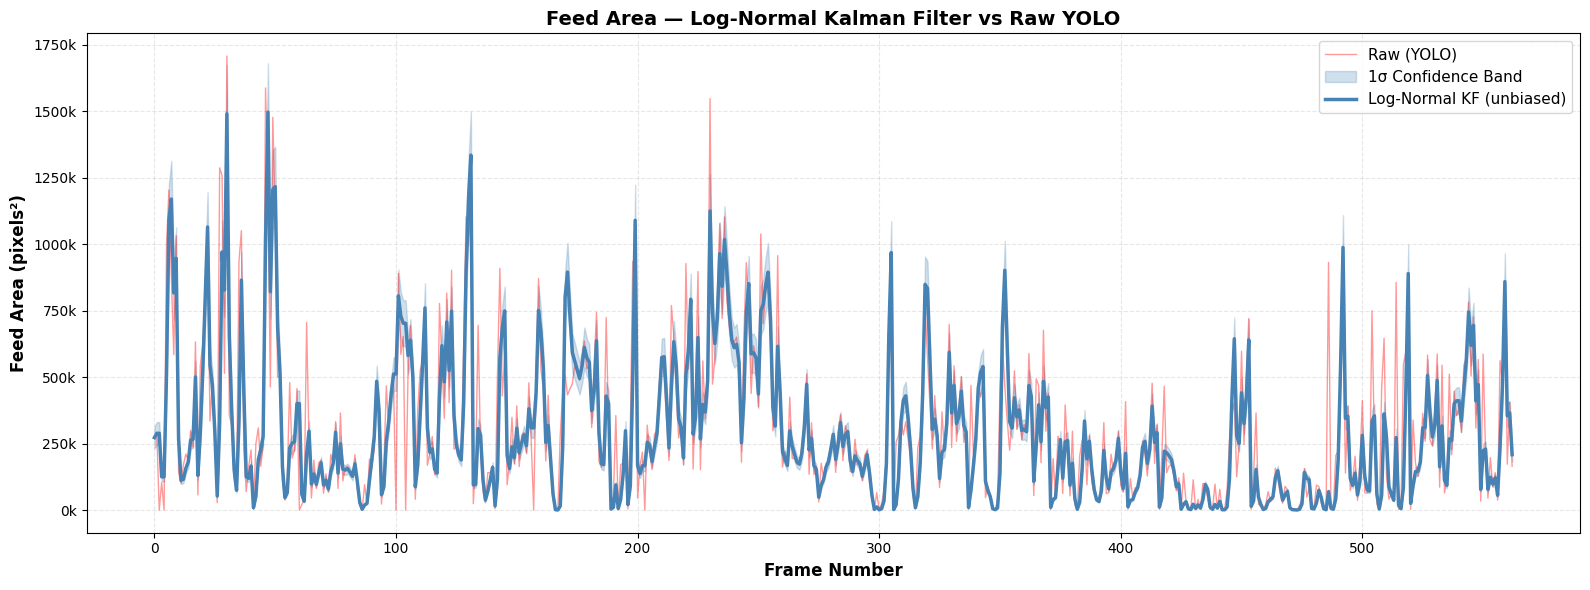

Saved: feed_amount_analysis.png


In [8]:
fig, ax = plt.subplots(figsize=(16, 6))

# Raw measurements
ax.plot(frame_numbers, feed_areas_raw,
        label='Raw (YOLO)', color='red', alpha=0.4, linewidth=1.0)

# 1-sigma confidence band from filter covariance
ax.fill_between(frame_numbers, conf_lower, conf_upper,
                alpha=0.25, color='steelblue', label='1σ Confidence Band')

# Unbiased filtered estimate
ax.plot(frame_numbers, feed_areas_filtered,
        label='Log-Normal KF (unbiased)', color='steelblue', linewidth=2.5)

ax.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax.set_ylabel('Feed Area (pixels²)', fontsize=12, fontweight='bold')
ax.set_title('Feed Area — Log-Normal Kalman Filter vs Raw YOLO', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3, linestyle='--')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

plt.tight_layout()
plt.savefig('feed_amount_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feed_amount_analysis.png")

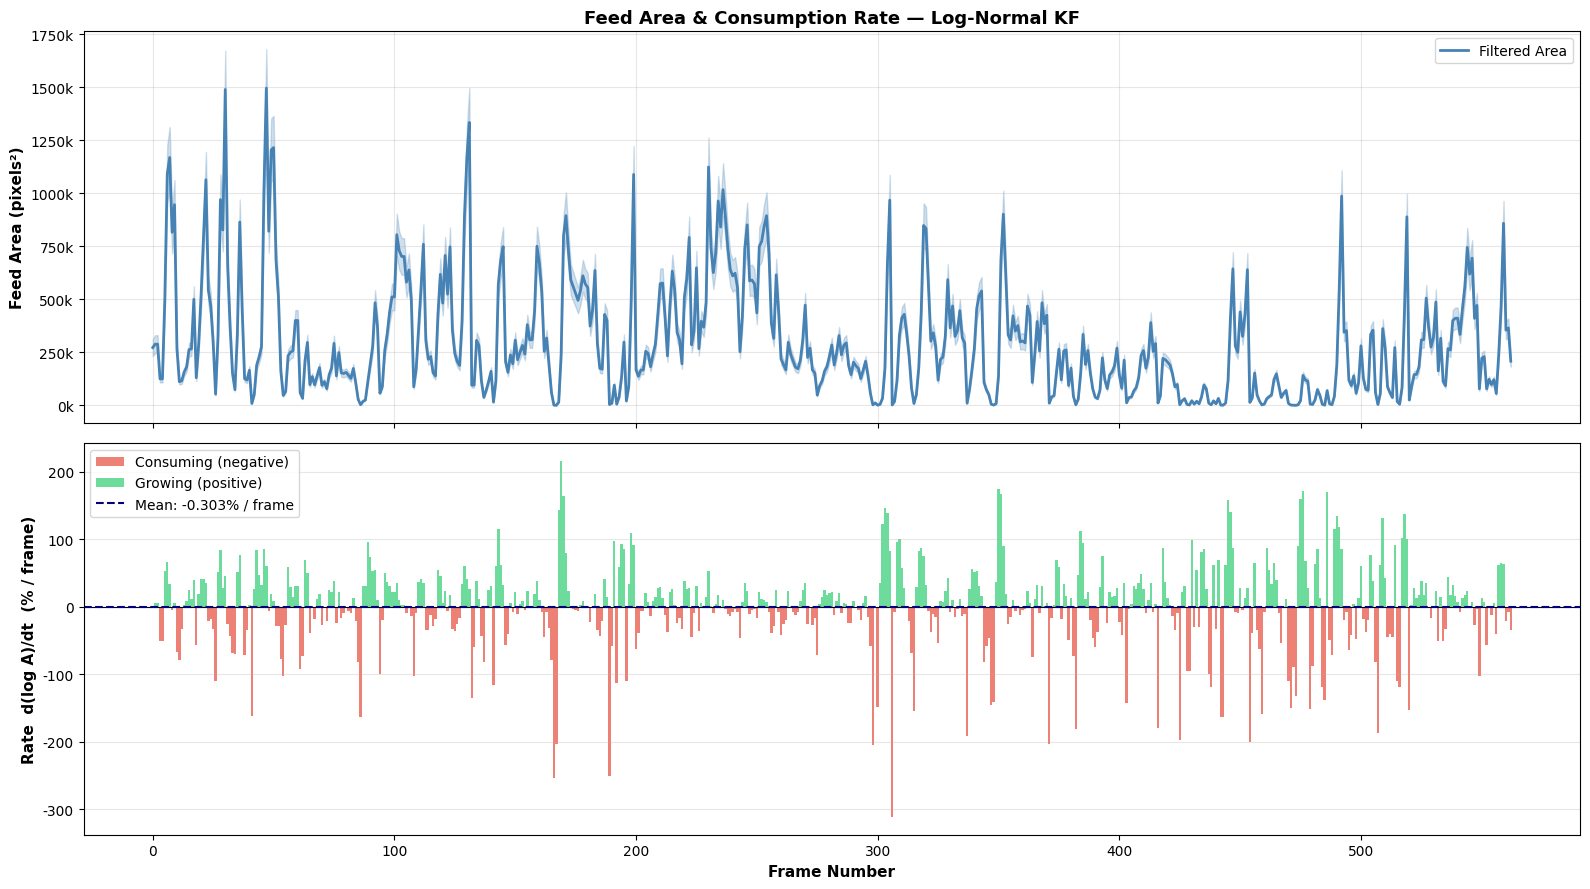

Saved: feed_consumption_rate.png


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

# ── Top: filtered area with confidence band ───────────────────────────────
axes[0].fill_between(frame_numbers, conf_lower, conf_upper,
                     alpha=0.25, color='steelblue')
axes[0].plot(frame_numbers, feed_areas_filtered,
             color='steelblue', linewidth=2, label='Filtered Area')
axes[0].set_ylabel('Feed Area (pixels²)', fontsize=11, fontweight='bold')
axes[0].set_title('Feed Area & Consumption Rate — Log-Normal KF', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# ── Bottom: consumption rate ──────────────────────────────────────────────
rate_pct = consumption_rates * 100   # convert to % / frame
colors = np.where(rate_pct < 0, '#e74c3c', '#2ecc71')
axes[1].bar(frame_numbers, rate_pct, color=colors, alpha=0.7, width=1.0)
axes[1].axhline(0, color='black', linewidth=0.8)

# Mark mean rate
mean_rate = rate_pct.mean()
axes[1].axhline(mean_rate, color='navy', linewidth=1.5, linestyle='--',
                label=f'Mean rate: {mean_rate:.3f}% / frame')

axes[1].set_xlabel('Frame Number', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rate  d(log A)/dt  (% / frame)', fontsize=11, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

from matplotlib.patches import Patch
axes[1].legend(handles=[
    Patch(facecolor='#e74c3c', alpha=0.7, label='Consuming (negative)'),
    Patch(facecolor='#2ecc71', alpha=0.7, label='Growing (positive)'),
    plt.Line2D([0], [0], color='navy', linestyle='--',
               label=f'Mean: {mean_rate:.3f}% / frame'),
], fontsize=10)

plt.tight_layout()
plt.savefig('feed_consumption_rate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feed_consumption_rate.png")

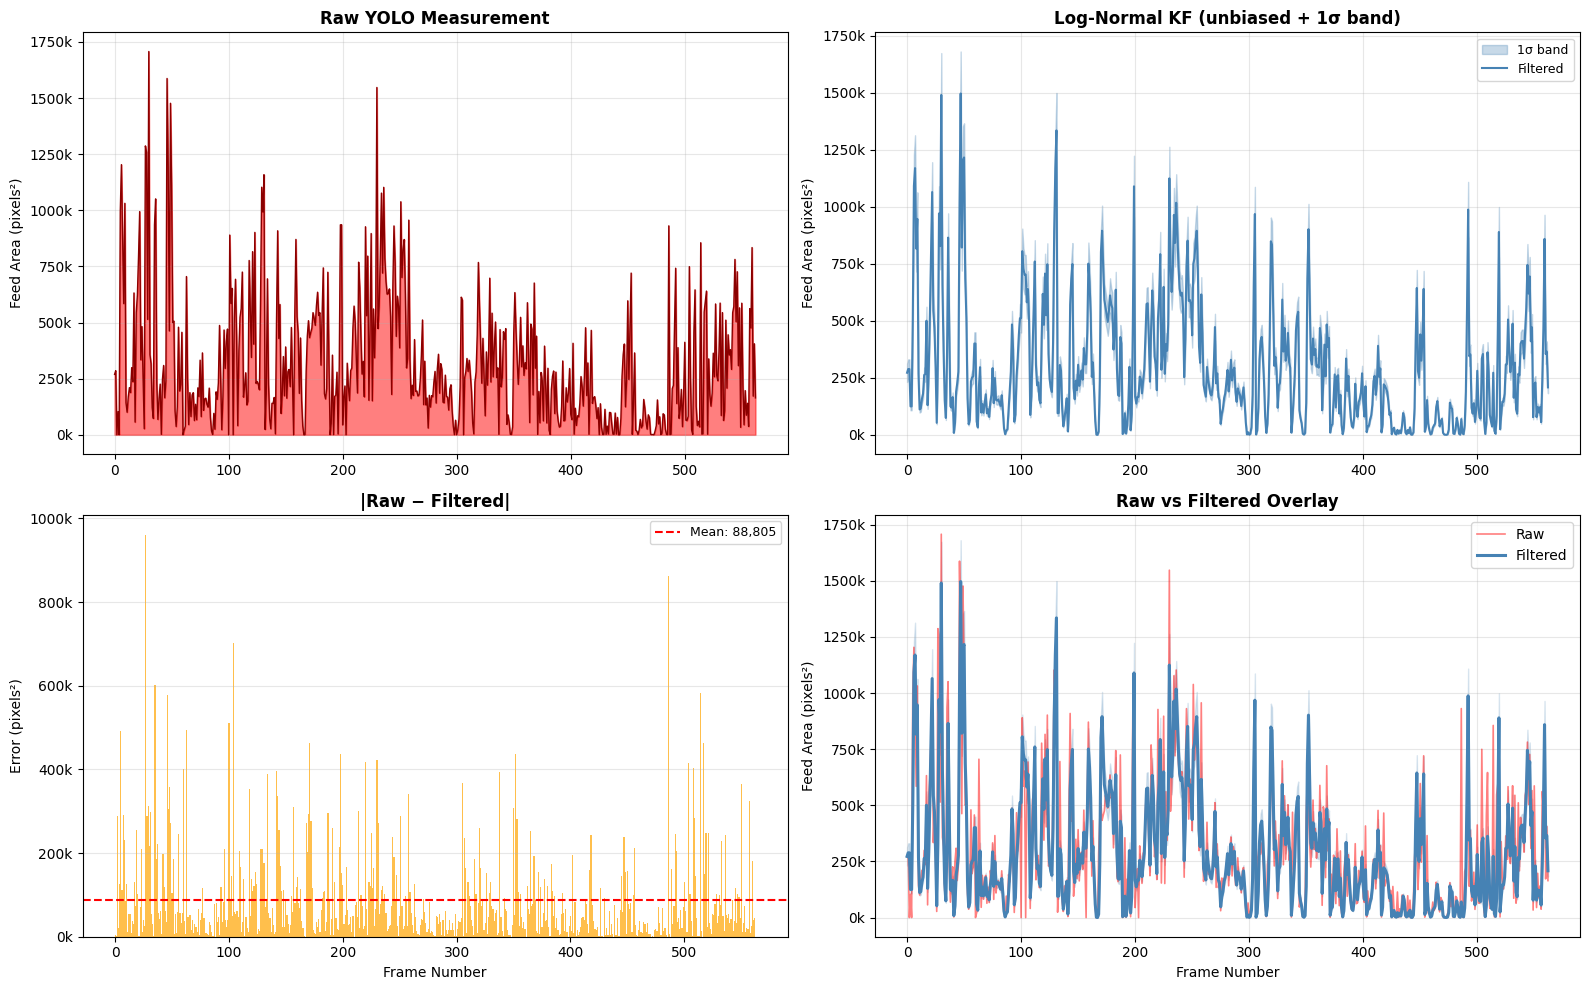

Saved: feed_amount_detailed_analysis.png


In [10]:
errors = np.abs(feed_areas_raw - feed_areas_filtered)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# ── Raw ───────────────────────────────────────────────────────────────────
axes[0, 0].fill_between(frame_numbers, feed_areas_raw, alpha=0.5, color='red')
axes[0, 0].plot(frame_numbers, feed_areas_raw, color='darkred', linewidth=1.0)
axes[0, 0].set_title('Raw YOLO Measurement', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# ── Log-Normal KF with confidence band ───────────────────────────────────
axes[0, 1].fill_between(frame_numbers, conf_lower, conf_upper,
                         alpha=0.3, color='steelblue', label='1σ band')
axes[0, 1].plot(frame_numbers, feed_areas_filtered,
                color='steelblue', linewidth=1.5, label='Filtered')
axes[0, 1].set_title('Log-Normal KF (unbiased + 1σ band)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# ── Filtering error ───────────────────────────────────────────────────────
axes[1, 0].bar(frame_numbers, errors, color='orange', alpha=0.7, width=1)
axes[1, 0].axhline(errors.mean(), color='red', linestyle='--', linewidth=1.5,
                    label=f'Mean: {errors.mean():,.0f}')
axes[1, 0].set_title('|Raw − Filtered|', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Frame Number', fontsize=10)
axes[1, 0].set_ylabel('Error (pixels²)', fontsize=10)
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(True, alpha=0.3, axis='y')
axes[1, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# ── Overlay ───────────────────────────────────────────────────────────────
axes[1, 1].plot(frame_numbers, feed_areas_raw,
                label='Raw', color='red', alpha=0.5, linewidth=1.2)
axes[1, 1].fill_between(frame_numbers, conf_lower, conf_upper,
                          alpha=0.2, color='steelblue')
axes[1, 1].plot(frame_numbers, feed_areas_filtered,
                label='Filtered', color='steelblue', linewidth=2.2)
axes[1, 1].set_title('Raw vs Filtered Overlay', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Frame Number', fontsize=10)
axes[1, 1].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

plt.tight_layout()
plt.savefig('feed_amount_detailed_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feed_amount_detailed_analysis.png")

## 7. Detailed Analysis - Error Display

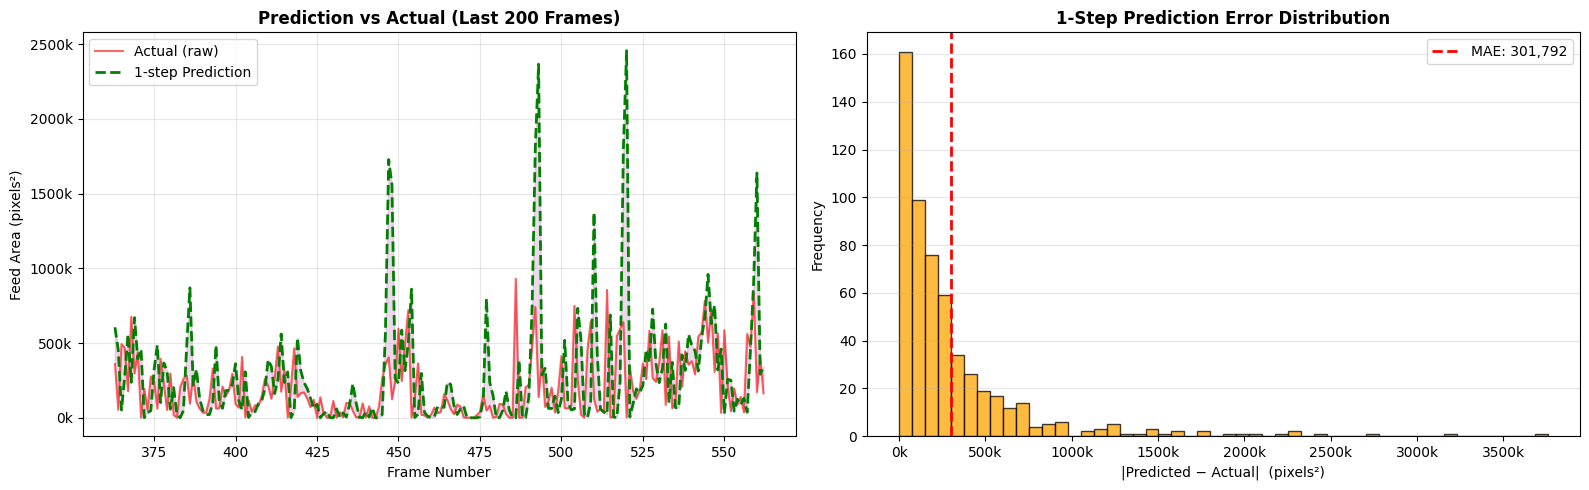

Saved: feed_amount_prediction_analysis.png


In [11]:
# predictions[t] was computed BEFORE update at frame t+1,
# so it is a genuine one-step-ahead forecast for raw[t+1].
prediction_errors = np.abs(predictions[:-1] - feed_areas_raw[1:])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── Left: predicted vs actual (last 200 frames) ───────────────────────────
n = min(200, len(frame_numbers))
f_recent  = frame_numbers[-n:]
act_recent = feed_areas_raw[-n:]
pred_recent = predictions[-n - 1:-1]   # shift by 1: pred[t] → actual[t+1]

axes[0].plot(f_recent, act_recent,
             label='Actual (raw)', color='red', alpha=0.6, linewidth=1.5)
axes[0].plot(f_recent, pred_recent,
             label='1-step Prediction', color='green', linewidth=2,
             linestyle='--')
axes[0].fill_between(f_recent, act_recent, pred_recent, alpha=0.15, color='purple')
axes[0].set_title(f'Prediction vs Actual (Last {n} Frames)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Frame Number', fontsize=10)
axes[0].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# ── Right: prediction error distribution ─────────────────────────────────
axes[1].hist(prediction_errors, bins=50, color='orange', alpha=0.75, edgecolor='black')
axes[1].axvline(prediction_errors.mean(), color='red', linestyle='--', linewidth=2,
                label=f'MAE: {prediction_errors.mean():,.0f}')
axes[1].set_title('1-Step Prediction Error Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('|Predicted − Actual|  (pixels²)', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

plt.tight_layout()
plt.savefig('feed_amount_prediction_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feed_amount_prediction_analysis.png")

## 8. Prediction Performance Analysis

In [12]:
print("=" * 60)
print("Log-Normal KF — 預測性能 (1-step ahead)")
print("=" * 60)

mape = np.mean(np.abs((feed_areas_raw[1:] - predictions[:-1])
                       / (feed_areas_raw[1:] + 1e-5))) * 100
rmse = np.sqrt(np.mean(prediction_errors ** 2))

print(f"\n  MAE:  {prediction_errors.mean():>12,.0f} pixels²")
print(f"  MAPE: {mape:>11.2f} %")
print(f"  RMSE: {rmse:>12,.0f} pixels²")
print(f"  Max:  {prediction_errors.max():>12,.0f} pixels²")

# Compare to naive persistence baseline (predict next = current raw)
naive_errors = np.abs(feed_areas_raw[:-1] - feed_areas_raw[1:])
print(f"\n  Naive persistence MAE (baseline): {naive_errors.mean():,.0f} pixels²")
improvement = (1 - prediction_errors.mean() / naive_errors.mean()) * 100
print(f"  Improvement over baseline:        {improvement:.1f}%")

Log-Normal KF — 預測性能 (1-step ahead)

  MAE:       301,792 pixels²
  MAPE: 49876882051.09 %
  RMSE:      522,511 pixels²
  Max:     3,755,686 pixels²

  Naive persistence MAE (baseline): 212,393 pixels²
  Improvement over baseline:        -42.1%


## 9. Prediction Statistics

In [13]:
def sweep_lognormal_kf(sigma_R_values, sigma_Q_values, reject_outliers=False):
    """Grid search over sigma_R × sigma_Q × outlier rejection."""
    results = []
    for sR in sigma_R_values:
        for sQ in sigma_Q_values:
            kf_t = LogNormalKalmanFilter(
                sigma_R=sR, 
                sigma_Q=sQ,
                reject_outliers=reject_outliers
            )
            filtered, preds = [], []
            for z in feed_areas_raw:
                filtered.append(kf_t.update(z))
                preds.append(kf_t.predict_next())
            filtered = np.array(filtered)
            preds    = np.array(preds)

            # Evaluate in log space (natural for this model)
            log_raw      = np.log(feed_areas_raw + 1)
            log_filtered = np.log(filtered + 1)
            log_mae  = np.mean(np.abs(log_raw - log_filtered))

            # Also track 1-step prediction MAE in pixel space
            pred_mae = np.mean(np.abs(preds[:-1] - feed_areas_raw[1:]))

            results.append({
                'sigma_R': sR, 
                'sigma_Q': sQ,
                'reject_outliers': reject_outliers,
                'log_mae': log_mae, 
                'pred_mae': pred_mae,
                'filtered': filtered,
                'std': np.std(filtered)
            })
    return results


print("=" * 70)
print("Parameter sweep: sigma_R × sigma_Q × outlier rejection")
print("=" * 70)

sR_vals = [0.10, 0.15, 0.20]
sQ_vals = [1e-3, 5e-3, 1e-2]

# Test with and without outlier rejection
sweep_no_reject = sweep_lognormal_kf(sR_vals, sQ_vals, reject_outliers=False)
sweep_reject = sweep_lognormal_kf(sR_vals, sQ_vals, reject_outliers=True)

all_results = sweep_no_reject + sweep_reject

print(f"\n{'sigma_R':>8}  {'sigma_Q':>10}  {'Reject':>6}  {'log-MAE':>10}  {'std':>12}  {'pred-MAE':>15}")
print("-" * 75)

# Show best 10 by log-MAE
for r in sorted(all_results, key=lambda x: x['log_mae'])[:10]:
    print(f"  {r['sigma_R']:>6.2f}  {r['sigma_Q']:>10.0e}  {str(r['reject_outliers']):>6}  "
          f"{r['log_mae']:>10.5f}  {r['std']:>12,.0f}  {r['pred_mae']:>15,.0f}")

Parameter sweep: sigma_R × sigma_Q × outlier rejection

 sigma_R     sigma_Q  Reject     log-MAE           std         pred-MAE
---------------------------------------------------------------------------
    0.10       1e-02   False     0.52650       273,730          350,092
    0.10       5e-03   False     0.58674       269,141          304,740
    0.15       1e-02   False     0.59751       269,384          301,792
    0.20       1e-02   False     0.64845       265,777          278,597
    0.15       5e-03   False     0.65867       263,180          271,384
    0.20       5e-03   False     0.71037       258,594          255,384
    0.10       1e-03   False     0.73089       254,165          246,786
    0.15       1e-03   False     0.80207       247,225          232,980
    0.20       1e-03   False     0.85216       242,899          228,918
    0.20       1e-02    True     1.32711     1,495,554          688,486


## 10. Tune Kalman Filter Parameters (Optional)

In [14]:
import pandas as pd

results_df = pd.DataFrame({
    'Frame':                frame_numbers,
    'Raw_Feed_Area':        feed_areas_raw,
    'Filtered_Feed_Area':   feed_areas_filtered,
    'Consumption_Rate':     consumption_rates,       # d(log A)/dt [1/frame]
    'Consumption_Rate_Pct': consumption_rates * 100, # % / frame
    'Predicted_Feed_Area':  predictions,             # true 1-step-ahead
    'Conf_Lower_1sigma':    conf_lower,
    'Conf_Upper_1sigma':    conf_upper,
    'Filtering_Error':      np.abs(feed_areas_raw - feed_areas_filtered),
})

csv_path = 'feed_amount_analysis_results.csv'
results_df.to_csv(csv_path, index=False)
print(f"Saved: {csv_path}")

print("\nData preview (first 10 rows):")
print(results_df.head(10).to_string())

print("\nSummary:")
print(results_df.describe())

Saved: feed_amount_analysis_results.csv

Data preview (first 10 rows):
   Frame  Raw_Feed_Area  Filtered_Feed_Area  Consumption_Rate  Consumption_Rate_Pct  Predicted_Feed_Area  Conf_Lower_1sigma  Conf_Upper_1sigma  Filtering_Error
0      0   2.693473e+05        2.723945e+05          0.000000              0.000000         4.496643e+05       2.318293e+05       3.129368e+05      3047.149630
1      1   2.856888e+05        2.884859e+05          0.056512              5.651198         3.195402e+05       2.459818e+05       3.309668e+05      2797.144056
2      2   0.000000e+00        2.884859e+05          0.056512              5.651198         3.195402e+05       2.459818e+05       3.309668e+05    288485.894056
3      3   1.036562e+05        1.248833e+05         -0.512458            -51.245785         7.646080e+04       1.078739e+05       1.418853e+05     21227.056082
4      4   0.000000e+00        1.248833e+05         -0.512458            -51.245785         7.646080e+04       1.078739e+05      

## 11. Export Result Data

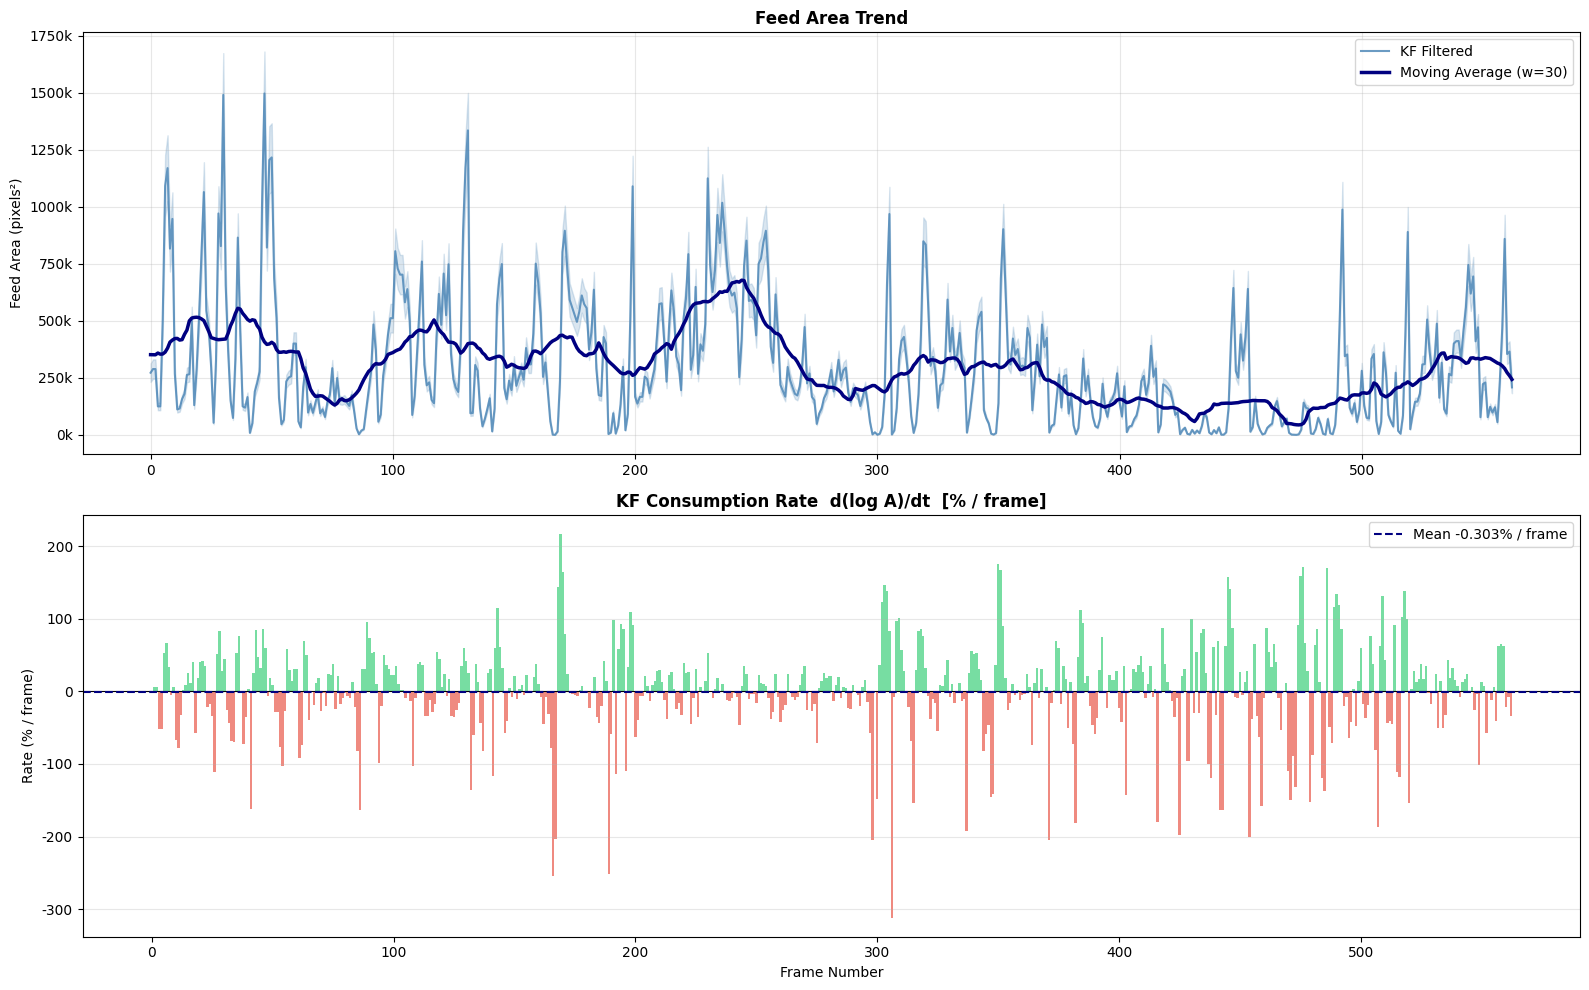

Saved: feed_amount_trend_analysis.png


In [15]:
window_size = 30
ma_filtered = uniform_filter1d(feed_areas_filtered, size=window_size, mode='nearest')

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# ── Top: area + moving average ────────────────────────────────────────────
axes[0].fill_between(frame_numbers, conf_lower, conf_upper,
                     alpha=0.2, color='steelblue')
axes[0].plot(frame_numbers, feed_areas_filtered,
             label='KF Filtered', color='steelblue', linewidth=1.5, alpha=0.8)
axes[0].plot(frame_numbers, ma_filtered,
             label=f'Moving Average (w={window_size})', color='navy', linewidth=2.5)
axes[0].set_title('Feed Area Trend', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# ── Bottom: KF rate (replaces naive finite-difference) ───────────────────
rate_pct = consumption_rates * 100
col = np.where(rate_pct < 0, '#e74c3c', '#2ecc71')
axes[1].bar(frame_numbers, rate_pct, color=col, alpha=0.65, width=1.0)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].axhline(rate_pct.mean(), color='navy', linewidth=1.5, linestyle='--',
                label=f'Mean {rate_pct.mean():.3f}% / frame')
axes[1].set_title('KF Consumption Rate  d(log A)/dt  [% / frame]',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Frame Number', fontsize=10)
axes[1].set_ylabel('Rate (% / frame)', fontsize=10)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('feed_amount_trend_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feed_amount_trend_analysis.png")

## 12. Advanced Analysis - Trend Detection

In [16]:
print("\n" + "=" * 70)
print(" " * 15 + "飼料量分析 — Log-Normal KF 完整報告")
print("=" * 70)

print(f"\n【基本信息】")
print(f"  視頻文件:    {CONFIG['video_path']}")
print(f"  YOLO 模型:   {CONFIG['model_path']}")
print(f"  處理幀數:    {len(frame_numbers)}")
print(f"  視頻時長:    {len(frame_numbers)/fps:.2f} 秒")
print(f"  信心度閾值:  {CONFIG['confidence_threshold']}")

print(f"\n【模型參數】")
print(f"  sigma_R (測量噪聲 std, log space): {CONFIG['sigma_R']}")
print(f"  sigma_Q (過程噪聲強度):            {CONFIG['sigma_Q']}")
print(f"  狀態向量: [log_area, consumption_rate]")
print(f"  初始化:   以第一幀 log(z₀) 初始化，避免收斂延遲")

print(f"\n【飼料面積統計】")
print(f"  原始值:   {feed_areas_raw.min():,.0f} ~ {feed_areas_raw.max():,.0f} pixels²  (std={feed_areas_raw.std():,.0f})")
print(f"  濾波後:   {feed_areas_filtered.min():,.0f} ~ {feed_areas_filtered.max():,.0f} pixels²  (std={feed_areas_filtered.std():,.0f})")
print(f"  降噪效果: {noise_reduction:.1f}%")

print(f"\n【消耗速率 d(log A)/dt】")
print(f"  均值:     {consumption_rates.mean()*100:.4f}% / frame  →  {consumption_rates.mean()*100*fps:.3f}% / sec")
print(f"  標準差:   {consumption_rates.std()*100:.4f}% / frame")
print(f"  最小值:   {consumption_rates.min()*100:.4f}% / frame  (最快消耗)")
print(f"  最大值:   {consumption_rates.max()*100:.4f}% / frame  (最快增加)")

print(f"\n【預測性能 (1-step ahead)】")
print(f"  MAE:   {prediction_errors.mean():,.0f} pixels²")
print(f"  MAPE:  {mape:.2f}%")
print(f"  RMSE:  {rmse:,.0f} pixels²")
print(f"  vs naive baseline MAE: {naive_errors.mean():,.0f}  → improvement {improvement:.1f}%")

print(f"\n【輸出文件】")
print(f"  ✓ feed_amount_analysis.png          — 主要對比圖 (含信心帶)")
print(f"  ✓ feed_consumption_rate.png         — 消耗速率分析圖")
print(f"  ✓ feed_amount_detailed_analysis.png — 4格詳細分析")
print(f"  ✓ feed_amount_prediction_analysis.png — 真實1步預測")
print(f"  ✓ feed_amount_trend_analysis.png    — 趨勢 + KF 速率")
print(f"  ✓ feed_amount_analysis_results.csv  — 含 Consumption_Rate 欄位")

print("\n" + "=" * 70)
print("分析完成！")
print("=" * 70)


               飼料量分析 — Log-Normal KF 完整報告

【基本信息】
  視頻文件:    data/fish_feeding.mp4
  YOLO 模型:   models/yoloFish.pt
  處理幀數:    563
  視頻時長:    18.77 秒
  信心度閾值:  0.35

【模型參數】
  sigma_R (測量噪聲 std, log space): 0.15
  sigma_Q (過程噪聲強度):            0.01
  狀態向量: [log_area, consumption_rate]
  初始化:   以第一幀 log(z₀) 初始化，避免收斂延遲

【飼料面積統計】
  原始值:   0 ~ 1,707,559 pixels²  (std=286,922)
  濾波後:   181 ~ 1,496,583 pixels²  (std=269,384)
  降噪效果: 6.1%

【消耗速率 d(log A)/dt】
  均值:     -0.3026% / frame  →  -9.079% / sec
  標準差:   64.5949% / frame
  最小值:   -311.5609% / frame  (最快消耗)
  最大值:   216.4388% / frame  (最快增加)

【預測性能 (1-step ahead)】
  MAE:   301,792 pixels²
  MAPE:  49876882051.09%
  RMSE:  522,511 pixels²
  vs naive baseline MAE: 212,393  → improvement -42.1%

【輸出文件】
  ✓ feed_amount_analysis.png          — 主要對比圖 (含信心帶)
  ✓ feed_consumption_rate.png         — 消耗速率分析圖
  ✓ feed_amount_detailed_analysis.png — 4格詳細分析
  ✓ feed_amount_prediction_analysis.png — 真實1步預測
  ✓ feed_amount_trend_analysis.png    — 趨勢 + K

## 13. Summary Report

In [ ]:
print("\n" + "=" * 70)
print(" " * 20 + "飼料量分析 - 完整報告")
print("=" * 70)

print(f"\n【基本信息】")
print(f"  視頻文件: {CONFIG['video_path']}")
print(f"  YOLO 模型: {CONFIG['model_path']}")
print(f"  處理幀數: {len(frame_numbers)}")
print(f"  視頻時長: {len(frame_numbers)/fps:.2f} 秒")
print(f"  信心度閾值: {CONFIG['confidence_threshold']}")

print(f"\n【飼料面積統計】")
print(f"  原始值範圍: {feed_areas_raw.min():,.0f} ~ {feed_areas_raw.max():,.0f} pixels²")
print(f"  濾波值範圍: {feed_areas_filtered.min():,.0f} ~ {feed_areas_filtered.max():,.0f} pixels²")
print(f"  原始平均值: {feed_areas_raw.mean():,.0f} pixels²")
print(f"  濾波平均值: {feed_areas_filtered.mean():,.0f} pixels²")

print(f"\n【Kalman Filter 參數】")
print(f"  測量噪聲 (sigma_R): {CONFIG['sigma_R']}")
print(f"  過程噪聲 (sigma_Q): {CONFIG['sigma_Q']}")
print(f"  異常值拒絕: {CONFIG['reject_outliers']}")
print(f"  降噪效率: {noise_reduction:.1f}%")

print(f"\n【預測性能】")
print(f"  平均絕對誤差 (MAE): {prediction_errors.mean():,.0f} pixels²")
print(f"  平均百分比誤差 (MAPE): {mape:.2f}%")
print(f"  均方根誤差 (RMSE): {np.sqrt(np.mean(prediction_errors**2)):,.0f} pixels²")

print(f"\n【輸出文件】")
print(f"  ✓ feed_amount_analysis.png - 主要對比圖")
print(f"  ✓ feed_amount_detailed_analysis.png - 詳細分析圖")
print(f"  ✓ feed_amount_prediction_analysis.png - 預測性能圖")
print(f"  ✓ feed_amount_trend_analysis.png - 趨勢分析圖")
print(f"  ✓ feed_amount_analysis_results.csv - 數據導出")

print("\n" + "=" * 70)
print("分析完成！")
print("=" * 70)